In [142]:
import pandas as pd
import numpy as np

from sklearn.metrics.pairwise import cosine_similarity
import ast


In [143]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [144]:
ads_base = pd.read_csv('/content/drive/MyDrive/RAIA/Projetos/NATION/ads.csv')
users_base = pd.read_csv('/content/drive/MyDrive/RAIA/Projetos/NATION/users.csv')

users= users_base.copy()
ads = ads_base.copy()

In [145]:
users.head(1)

,user_id,age,gender,lat,lon,preferences
0,0,45,F,-33.106155,-53.58914,"[('Game_Hardware', 0.8485463411219264), ('Game..."


In [146]:
ads.head(1)

,ad_id,lat_target,lon_target,location_sensitive,max_radius_km,min_age,max_age,is_any_age,gender_target,categories,bid,budget,trust_score,estimated_conversion_rate,click_probability
0,0,1.285495,-61.053986,0,2000,0,100,True,F,"{'Game_Development': 0.03083668354262722, 'For...",15.0,15000.0,0.988041,0.015604,0.031313


In [147]:
ads["categories"].head()

,categories
0,"{'Game_Development': 0.03083668354262722, 'For..."
1,"{'MOBA': 0.08566344789189491, 'Mobile_Gaming':..."
2,"{'Sports_Games': 0.49102780454698103, 'Minecra..."
3,"{'Game_Hardware': 0.37218099077587796, 'Open_W..."
4,"{'MMORPG': 0.9785586009059007, 'PC_Gaming': 0...."


In [148]:
type(users.preferences)

pandas.core.series.Series

In [149]:
# CSV perde a informação de tipo, então precisamos converter as strings de volta para listas e para dicionários. Para isso, podemos usar a função ast.literal_eval, que avalia uma string como uma expressão Python e retorna o objeto correspondente.

users["preferences"] = users["preferences"].apply(ast.literal_eval)
ads['categories'] = ads['categories'].apply(ast.literal_eval)

# Features Categorias

Gerar as categorias com seus pesos

OBS: isso foi feito porque para trabalhar com a abordagem de vetores, ADS e Users devem possuir mesma dimensões

Depois desenvolver uma forma mais inteligente para não fazer à mão

In [150]:
all_categories  = [
"FPS",
"Battle_Royale",
"MOBA",
"RPG",
"MMORPG",
"Strategy",
"Simulation",
"Sports_Games",
"Racing",
"Indie_Games",
"Retro_Gaming",
"Mobile_Gaming",
"PC_Gaming",
"Console_Gaming",
"Game_Development",
"Game_Streaming",
"Esports",
"Game_Hardware",
"VR_Gaming",
"Open_World",
"League_of_Legends",
"Fortnite",
"Minecraft",
"Counter_Strike",
"World_of_Warcraft"
]

In [151]:
# enumerar as categorias para criar um índice de categoria, que será usado para construir os vetores de características dos usuários e dos anúncios.
category_index = {cat: i for i, cat in enumerate(all_categories)}


In [152]:
category_index

{'FPS': 0,
 'Battle_Royale': 1,
 'MOBA': 2,
 'RPG': 3,
 'MMORPG': 4,
 'Strategy': 5,
 'Simulation': 6,
 'Sports_Games': 7,
 'Racing': 8,
 'Indie_Games': 9,
 'Retro_Gaming': 10,
 'Mobile_Gaming': 11,
 'PC_Gaming': 12,
 'Console_Gaming': 13,
 'Game_Development': 14,
 'Game_Streaming': 15,
 'Esports': 16,
 'Game_Hardware': 17,
 'VR_Gaming': 18,
 'Open_World': 19,
 'League_of_Legends': 20,
 'Fortnite': 21,
 'Minecraft': 22,
 'Counter_Strike': 23,
 'World_of_Warcraft': 24}

In [153]:
# função para construir o vetor de características do usuário a partir de suas preferências, usando o índice de categoria para mapear as categorias para posições no vetor.

def build_user_vector(preferences, category_index):

    vector = np.zeros(len(category_index))

    for category, weight in preferences:
        if category in category_index:
            vector[category_index[category]] = weight

    return vector

In [154]:
# fazendo um teste para ver se a função build_user_vector está funcionando corretamente, construindo o vetor de características do primeiro usuário do dataset.
teste = build_user_vector(users.iloc[0]['preferences'], category_index)
display(teste)
display(users.iloc[0]['preferences'])
display(category_index)

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.15145366,
       0.        , 0.        , 0.84854634, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ])

[('Game_Hardware', 0.8485463411219264),
 ('Game_Development', 0.15145365887807363)]

{'FPS': 0,
 'Battle_Royale': 1,
 'MOBA': 2,
 'RPG': 3,
 'MMORPG': 4,
 'Strategy': 5,
 'Simulation': 6,
 'Sports_Games': 7,
 'Racing': 8,
 'Indie_Games': 9,
 'Retro_Gaming': 10,
 'Mobile_Gaming': 11,
 'PC_Gaming': 12,
 'Console_Gaming': 13,
 'Game_Development': 14,
 'Game_Streaming': 15,
 'Esports': 16,
 'Game_Hardware': 17,
 'VR_Gaming': 18,
 'Open_World': 19,
 'League_of_Legends': 20,
 'Fortnite': 21,
 'Minecraft': 22,
 'Counter_Strike': 23,
 'World_of_Warcraft': 24}

In [155]:
len(teste)

25

In [156]:
# função análoga para o ads
# feito isso pq o ads foi salvo como dict e user como list

def build_ad_vector(categories, category_index):

    vector = np.zeros(len(category_index))

    for category, weight in categories.items():
        if category in category_index:
            vector[category_index[category]] = weight

    return vector

In [157]:
# teste para ads
teste_ad = build_ad_vector(ads.iloc[0]['categories'], category_index)
display(teste_ad)
display(ads.iloc[0]['categories'])


array([0.        , 0.        , 0.        , 0.        , 0.35456129,
       0.        , 0.        , 0.01817338, 0.        , 0.03925901,
       0.        , 0.        , 0.        , 0.        , 0.03083668,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.17101861, 0.11956046, 0.        , 0.26659057, 0.        ])

{'Game_Development': 0.03083668354262722,
 'Fortnite': 0.11956046184830019,
 'Sports_Games': 0.018173378487163622,
 'MMORPG': 0.35456128766617023,
 'League_of_Legends': 0.17101861324341172,
 'Counter_Strike': 0.266590565443359,
 'Indie_Games': 0.03925900976896807}

In [158]:
# aplcar as funções para construir os vetores de características para todos os usuários e anúncios, e armazenar esses vetores em novas colunas nos dataframes.

users['feature_vector'] = users['preferences'].apply(lambda prefs: build_user_vector(prefs, category_index))
ads['feature_vector'] = ads['categories'].apply(lambda cats: build_ad_vector(cats, category_index))

In [159]:
# validaçao dos vetores para detectar vetores zerados
print("Users com vetor zero:", (users['feature_vector'].apply(sum) == 0).sum())
print("Ads com vetor zero:", (ads['feature_vector'].apply(sum) == 0).sum())

Users com vetor zero: 0
Ads com vetor zero: 0


In [160]:
users.head(1)

,user_id,age,gender,lat,lon,preferences,feature_vector
0,0,45,F,-33.106155,-53.58914,"[(Game_Hardware, 0.8485463411219264), (Game_De...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."


# Gerar os vetores finais

- vai fazer a similaridade tudo junto ou vai separar??

In [161]:
# definir ordem fixa das features

CATEGORY_COLUMNS = all_categories

In [162]:
# transformar features_vector em colunas separadas
category_features_users = pd.DataFrame(
    users["feature_vector"].tolist(),
    columns=CATEGORY_COLUMNS
)

category_features_ads = pd.DataFrame(
    ads["feature_vector"].tolist(),
    columns=CATEGORY_COLUMNS
)

users = pd.concat([users, category_features_users], axis=1)
ads = pd.concat([ads, category_features_ads], axis=1)

# Gerar os vetores finais sem cidade/estado

In [163]:
category_features_users

,FPS,Battle_Royale,MOBA,RPG,MMORPG,Strategy,Simulation,Sports_Games,Racing,Indie_Games,...,Game_Streaming,Esports,Game_Hardware,VR_Gaming,Open_World,League_of_Legends,Fortnite,Minecraft,Counter_Strike,World_of_Warcraft
0,0.000000,0.000000,0.0,0.000000,0.0,0.000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.848546,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000
1,0.000000,0.000000,0.0,0.000000,0.0,0.000,0.000000,0.717441,0.000000,0.282559,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000
2,0.000000,0.000000,0.0,0.000000,0.0,0.000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.0,0.000000,0.0,0.000,0.040488,0.000000,0.000000,0.138106,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.149990,0.179896
4,0.000000,0.000000,0.0,0.319278,0.0,0.000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.680722,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,0.000000,0.000000,0.0,0.199963,0.0,0.000,0.000000,0.000000,0.575985,0.000000,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.007961
9996,0.000000,0.000000,0.0,0.000000,0.0,0.000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.537227,0.000000,0.000000
9997,0.156999,0.407886,0.0,0.000000,0.0,0.000,0.373462,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.061653,0.000000
9998,0.000000,0.574812,0.0,0.000000,0.0,0.000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.425188


In [164]:
users.iloc[0].preferences

[('Game_Hardware', 0.8485463411219264),
 ('Game_Development', 0.15145365887807363)]

In [165]:
users[category_features_users.columns].iloc[0]

,0
FPS,0.000000
Battle_Royale,0.000000
MOBA,0.000000
RPG,0.000000
MMORPG,0.000000
Strategy,0.000000
Simulation,0.000000
Sports_Games,0.000000
Racing,0.000000
Indie_Games,0.000000


In [166]:
FINAL_FEATURE_COLUMNS = (
    CATEGORY_COLUMNS
)

In [167]:
user_matrix = users[FINAL_FEATURE_COLUMNS].values
ad_matrix = ads[FINAL_FEATURE_COLUMNS].values

# PRECISA NORMALIZAR???

In [ ]:
# adicionando a normalizacao (melhora o cosine similarity) - senao o bid domina tudo no score
from sklearn.preprocessing import normalize

user_matrix = normalize(user_matrix)
ad_matrix = normalize(ad_matrix)

In [ ]:
user_matrix

array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.27153974, 0.70546243, 0.        , ..., 0.        , 0.10663164,
        0.        ],
       [0.        , 0.8039575 , 0.        , ..., 0.        , 0.        ,
        0.59468676],
       [0.00832669, 0.        , 0.        , ..., 0.        , 0.29713901,
        0.34680061]])

In [ ]:
similarity_matrix = cosine_similarity(user_matrix, ad_matrix)

In [ ]:
similarity_matrix
# cada linha representa um usuário e cada coluna representa um anúncio, e os valores são as similaridades entre eles.

array([[0.01098819, 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.0634668 , 0.        , 0.6460098 , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.05764941, 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.17108319, 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]])

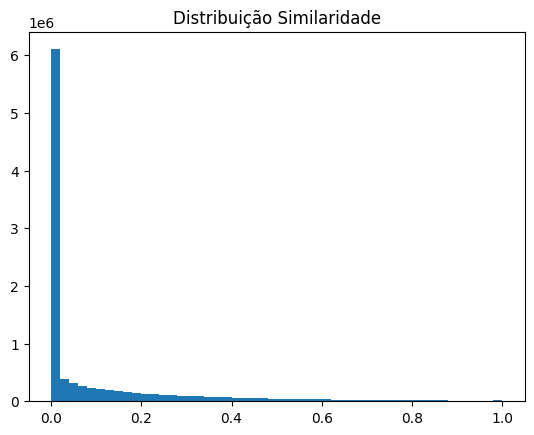

In [ ]:
# validando a distribuiçao
import matplotlib.pyplot as plt

plt.hist(similarity_matrix.flatten(), bins=50)
plt.title("Distribuição Similaridade")
plt.show()

 -  - - senao     ## Validar os resultados

In [ ]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371

    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))

    return R * c

In [ ]:
user_index = 50

user_lat = users.iloc[user_index]["lat"]
user_lon = users.iloc[user_index]["lon"]

ads["distance_km"] = haversine(
    user_lat,
    user_lon,
    ads["lat_target"],
    ads["lon_target"]
)

tau = 200

ads["distance_score"] = np.exp(-ads["distance_km"] / tau)

ads.loc[
    ads["location_sensitive"] == 0,
    "distance_score"
] = 1

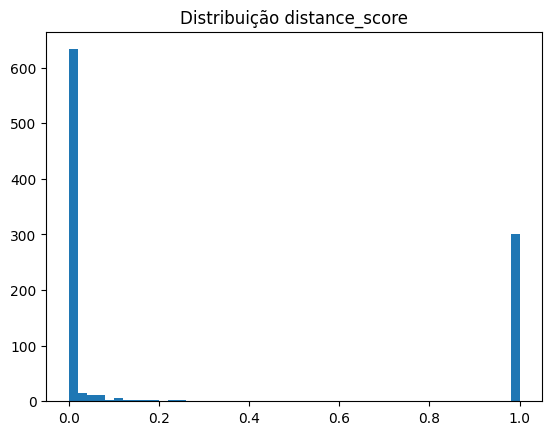

In [ ]:
# grafico
plt.hist(ads["distance_score"], bins=50)
plt.title("Distribuição distance_score")
plt.show()

# **OBJETIVO : score final**

score =
interest_similarity
× demographic_score
× bid
× trust_score
× estimated_conversion_rate

In [ ]:
user_gender = users.iloc[user_index]["gender"]
user_age = users.iloc[user_index]["age"]

scores = similarity_matrix[user_index]

distance_scores = ads["distance_score"].values

#final_scores = scores * distance_scores
def normalize(x):
    return (x - x.min()) / (x.max() - x.min() + 1e-9) # normaliza valores entre 0 e 1

business_score = (
    normalize(ads["bid"]) *
    normalize(ads["trust_score"]) *
    normalize(ads["estimated_conversion_rate"])
)

final_scores = scores * distance_scores * business_score.values

ads_filtered = ads[
    (ads["gender_target"].isin([user_gender, "Any"])) &
    (
        (ads["is_any_age"]) |
        ((ads["min_age"] <= user_age) & (user_age <= ads["max_age"]))
    ) &
    (
        ads["distance_km"] <= ads["max_radius_km"]
    )
]
filtered_scores = final_scores[ads_filtered.index.values]

top_ads = ads_filtered.index[filtered_scores.argsort()[::-1][:100]]

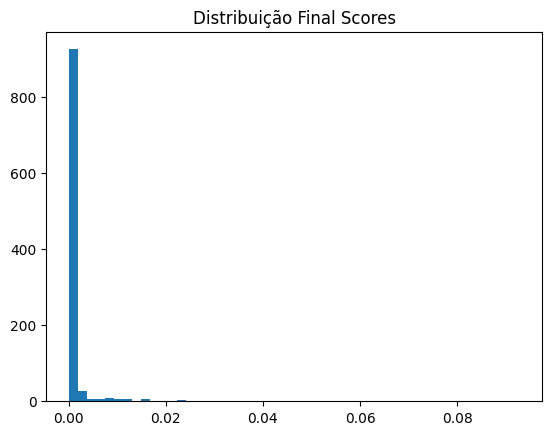

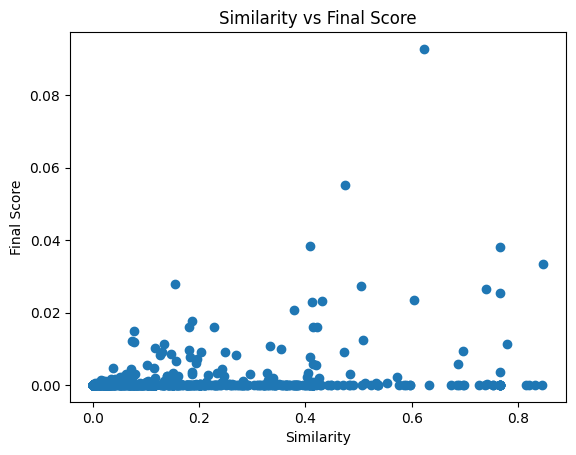

In [ ]:
# graficos principais
plt.hist(final_scores, bins=50)
plt.title("Distribuição Final Scores")
plt.show()

plt.scatter(scores, final_scores)
plt.title("Similarity vs Final Score")
plt.xlabel("Similarity")
plt.ylabel("Final Score")
plt.show()

In [ ]:
len(filtered_scores)

112

In [ ]:
top_ads

Index([968, 528, 967, 945,  11, 842, 284, 719, 907, 933,  13, 573, 918, 607,
       356, 707, 210, 276, 105, 436, 164, 993, 862, 226, 115, 816, 605, 916,
       988, 383, 609, 980, 320, 758, 740, 144, 132, 788, 280,  52, 694, 410,
       657,  44, 867, 238,  54, 979, 639, 651, 653, 675, 696, 682, 704, 700,
       745, 728, 735, 812, 805, 807, 782, 764, 844, 860, 840, 822, 826, 837,
       884, 881, 949, 937, 540, 571, 572, 636, 583, 627, 288, 333, 343, 376,
       378, 377, 411, 425, 445, 428, 444, 537, 486, 474, 465, 447, 157, 162,
       172, 173],
      dtype='int64')

In [ ]:
# df para explicabilidade
audit_df = pd.DataFrame({
    "ad_id": top_ads,
    "similarity": scores[top_ads],
    "distance": distance_scores[top_ads],
    "final_score": final_scores[top_ads]
}).sort_values("final_score", ascending=False)

display(audit_df.head(20))

,ad_id,similarity,distance,final_score
0,968,0.764812,1.000000,0.038078
1,528,0.508085,0.252205,0.012352
2,967,0.134445,1.000000,0.011423
3,945,0.334307,1.000000,0.010876
4,11,0.076773,1.000000,0.002469
5,842,0.062315,1.000000,0.001847
6,284,0.035123,1.000000,0.001586
7,719,0.022974,1.000000,0.001212
8,907,0.100063,1.000000,0.000820
9,933,0.511223,1.000000,0.000586


In [ ]:
#scores[top_ads]
final_scores[top_ads]

array([3.80776918e-02, 1.23515846e-02, 1.14231104e-02, 1.08763718e-02,
       2.46913857e-03, 1.84735570e-03, 1.58554815e-03, 1.21190740e-03,
       8.19899107e-04, 5.86195348e-04, 5.26282771e-04, 3.84563634e-04,
       3.22955140e-04, 1.23408649e-04, 1.03760780e-04, 9.72555621e-05,
       8.23373484e-05, 5.40502856e-05, 4.40876299e-05, 3.95260979e-05,
       3.60223020e-05, 2.72916275e-05, 1.41700461e-05, 1.25210222e-05,
       9.82386926e-06, 8.50717223e-06, 5.08882110e-06, 3.82664190e-06,
       1.23111147e-06, 9.99106346e-07, 7.72474359e-07, 6.65439612e-07,
       4.37531074e-07, 2.53117202e-07, 2.51639327e-07, 1.48646046e-07,
       7.84422661e-08, 2.88707313e-08, 1.53273321e-08, 1.14713986e-08,
       1.02290567e-08, 4.90172320e-10, 1.48723717e-10, 5.78532466e-11,
       2.53005741e-11, 1.84718185e-11, 6.65710180e-12, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
      

In [ ]:
ads_base.iloc[top_ads]

,ad_id,lat_target,lon_target,location_sensitive,max_radius_km,min_age,max_age,is_any_age,gender_target,categories,bid,budget,trust_score,estimated_conversion_rate,click_probability
968,968,-28.723493,-47.699725,0,500,18,27,False,F,{'Game_Development': 1.0},30.622132,30622.131744,0.760771,0.020215,0.038003
528,528,-27.169722,-54.163029,1,2000,0,100,True,Any,"{'VR_Gaming': 0.5294366601501723, 'Game_Develo...",26.431832,13215.916068,0.954867,0.039469,0.048849
967,967,-26.289807,-34.826003,0,2000,18,27,False,Any,"{'Minecraft': 0.33981558570240183, 'MMORPG': 0...",36.558602,18279.300889,0.971961,0.019052,0.017256
945,945,-5.214401,-58.797164,0,5000,0,100,True,Any,"{'Fortnite': 0.34426096173802456, 'Console_Gam...",27.395168,13697.583943,0.709218,0.018249,0.018508
11,11,-14.905991,-41.655697,0,5000,0,100,True,F,"{'FPS': 0.35970391571166505, 'Mobile_Gaming': ...",32.370477,32370.477098,0.945383,0.010150,0.011971
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
447,447,-33.425381,-44.178440,1,2000,0,100,True,F,"{'Open_World': 0.9801781271671006, 'PC_Gaming'...",22.632010,22632.009846,0.539597,0.032075,0.018062
157,157,-6.309495,-64.670010,1,5000,18,27,False,F,"{'Counter_Strike': 0.2585051906371977, 'Mobile...",27.762964,2776.296449,0.877711,0.021198,0.011295
162,162,3.474464,-38.526774,0,5000,18,27,False,Any,{'Fortnite': 1.0},15.000000,15000.000000,0.975078,0.048284,0.027120
172,172,-12.217023,-71.494169,1,5000,0,100,True,F,"{'Simulation': 0.11336040338292365, 'World_of_...",15.000000,1500.000000,0.902438,0.033618,0.011160


In [ ]:
users_base.loc[user_index]

,50
user_id,50
age,23
gender,F
lat,-28.451879
lon,-51.765924
preferences,"[('Racing', 0.09784719095425211), ('Fortnite',..."


# Testes Unitários

In [168]:
# Elegibilidade

def test_eligibility():
    user = {"gender": "F", "age": 25}

    ad_ok = {
        "gender_target": "F",
        "min_age": 18,
        "max_age": 30,
        "is_any_age": False
    }

    ad_bad = {
        "gender_target": "M",
        "min_age": 18,
        "max_age": 30,
        "is_any_age": False
    }

    assert is_eligible(user, ad_ok)
    assert not is_eligible(user, ad_bad)


def test_any_gender():
    user = {"gender": "F", "age": 25}

    ad = {
        "gender_target": "Any",
        "min_age": 18,
        "max_age": 30,
        "is_any_age": False
    }

    assert is_eligible(user, ad)


def test_any_age():
    user = {"gender": "F", "age": 80}

    ad = {
        "gender_target": "F",
        "min_age": 18,
        "max_age": 30,
        "is_any_age": True
    }

    assert is_eligible(user, ad)


def test_score_calculation():
    """
    Testa se o score está sendo calculado corretamente.
    """

    ad = {
        "interest_similarity": 0.5,
        "demographic_score": 0.8,
        "bid": 2.0,
        "trust_score": 1.0,
        "estimated_conversion_rate": 0.25
    }

    score = compute_score(ad)

    # 0.5 * 0.8 * 2.0 * 1.0 * 0.25 = 0.2
    assert score == 0.2


def test_ranking():
    """
    Testa ranking baseado no score completo.
    """
    import numpy as np

    ads = [
        {
            "interest_similarity": 0.5,
            "demographic_score": 0.8,
            "bid": 2.0,
            "trust_score": 1.0,
            "estimated_conversion_rate": 0.25
        },
        {
            "interest_similarity": 0.9,
            "demographic_score": 0.7,
            "bid": 1.5,
            "trust_score": 1.0,
            "estimated_conversion_rate": 0.3
        },
        {
            "interest_similarity": 0.3,
            "demographic_score": 0.9,
            "bid": 3.0,
            "trust_score": 1.0,
            "estimated_conversion_rate": 0.2
        }
    ]

    scores = np.array([compute_score(ad) for ad in ads])
    ranking = scores.argsort()[::-1]

    # vamos garantir que o maior score vem primeiro
    assert scores[ranking[0]] == max(scores)


# EXECUÇÃO DOS TESTES

test_eligibility()
test_any_gender()
test_any_age()
test_score_calculation()
test_ranking()

print("todos os testes passaram")

✅ todos os testes passaram!
